# Final Project

### Import libraries

In [ ]:
%reset -f
from __future__ import print_function

import math
import numpy as np
import numpy.linalg as nla
import pandas as pd
import re
import six
from os.path import join
import tensorflow as tf
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from keras_tuner import HyperParameters
import keras_tuner as kt

# feel free to import other libraries as needed

import warnings
warnings.filterwarnings('ignore')

---

## Data Ingestion

Read the weather data from the local drive

In [ ]:
    # Read data
df = pd.read_csv("weatherAUS.csv",
                 sep=",",
                 encoding='latin-1'
                 )
    
print('Shape of data', df.shape)
df.head()



Shape of data (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


---

## Getting to know the data

### Overview

In [29]:
# Get a sense of our data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 142193 entries, 0 to 142192
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   Date           142193 non-null  datetime64[us]
 1   Location       142193 non-null  str           
 2   MinTemp        141556 non-null  float64       
 3   MaxTemp        141871 non-null  float64       
 4   Rainfall       140787 non-null  float64       
 5   Evaporation    81350 non-null   float64       
 6   Sunshine       74377 non-null   float64       
 7   WindGustDir    132863 non-null  str           
 8   WindGustSpeed  132923 non-null  float64       
 9   WindDir9am     132180 non-null  str           
 10  WindDir3pm     138415 non-null  str           
 11  WindSpeed9am   140845 non-null  float64       
 12  WindSpeed3pm   139563 non-null  float64       
 13  Humidity9am    140419 non-null  float64       
 14  Humidity3pm    138583 non-null  float64       
 15  Pressure9am

In [30]:

# Retreive the statistics of each feature
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,142193,2013-04-01 00:28:51.730816,2007-11-01 00:00:00,2011-01-06 00:00:00,2013-05-27 00:00:00,2015-06-12 00:00:00,2017-06-25 00:00:00,NaN
MinTemp,141556.0,12.1864,-8.5,7.6,12.0,16.8,33.9,6.403283
MaxTemp,141871.0,23.226784,-4.8,17.9,22.6,28.2,48.1,7.117618
Rainfall,140787.0,2.349974,0.0,0.0,0.0,0.8,371.0,8.465173
Evaporation,81350.0,5.469824,0.0,2.6,4.8,7.4,145.0,4.188537
Sunshine,74377.0,7.624853,0.0,4.9,8.5,10.6,14.5,3.781525
WindGustSpeed,132923.0,39.984292,6.0,31.0,39.0,48.0,135.0,13.588801
WindSpeed9am,140845.0,14.001988,0.0,7.0,13.0,19.0,130.0,8.893337
WindSpeed3pm,139563.0,18.637576,0.0,13.0,19.0,24.0,87.0,8.803345
Humidity9am,140419.0,68.84381,0.0,57.0,70.0,83.0,100.0,19.051293


In [31]:
# Convert the data column from type string to date
df['Date'] = pd.to_datetime(df['Date'])
print("Type of Date: ", df['Date'].dtype)
df['Date'].head()

Type of Date:  datetime64[us]


0   2008-12-01
1   2008-12-02
2   2008-12-03
3   2008-12-04
4   2008-12-05
Name: Date, dtype: datetime64[us]

### Examine Target

In [32]:
# Examine the target (RainTomorrow)
print(df['RainTomorrow'].value_counts(dropna=False, normalize=True))

RainTomorrow
No     0.775819
Yes    0.224181
Name: proportion, dtype: float64


In [33]:
# Drop the rows without target
df = df.dropna(subset=['RainTomorrow']).reset_index(drop=True)
print(df['RainTomorrow'].value_counts(dropna=False, normalize=True))

RainTomorrow
No     0.775819
Yes    0.224181
Name: proportion, dtype: float64


### Check for Missing Values

In [34]:
missing_values = df.isna().mean().sort_values(ascending=False) * 100
print(missing_values.round(1))

Sunshine         47.7
Evaporation      42.8
Cloud3pm         40.2
Cloud9am         37.7
Pressure9am       9.9
Pressure3pm       9.8
WindDir9am        7.0
WindGustDir       6.6
WindGustSpeed     6.5
WindDir3pm        2.7
Humidity3pm       2.5
Temp3pm           1.9
WindSpeed3pm      1.8
Humidity9am       1.2
Rainfall          1.0
RainToday         1.0
WindSpeed9am      0.9
Temp9am           0.6
MinTemp           0.4
MaxTemp           0.2
Date              0.0
Location          0.0
RainTomorrow      0.0
dtype: float64


In [37]:
# Examine which location is missing feature.
df.groupby('Location')[['Sunshine', 'Evaporation']].apply(lambda s: s.isna().mean() * 100).round(1).sort_values('Sunshine')

,Sunshine,Evaporation
Location,,
Melbourne,0.0,0.0
Watsonia,0.0,0.1
MelbourneAirport,0.0,0.1
Darwin,0.1,1.7
Perth,0.2,0.0
PerthAirport,0.2,0.0
PearceRAAF,0.2,100.0
Hobart,0.4,0.2
Sydney,0.5,1.5


### Distribution and Outliers


Location 49
WindGustDir 16
WindDir9am 16
WindDir3pm 16
RainToday 2
RainTomorrow 2


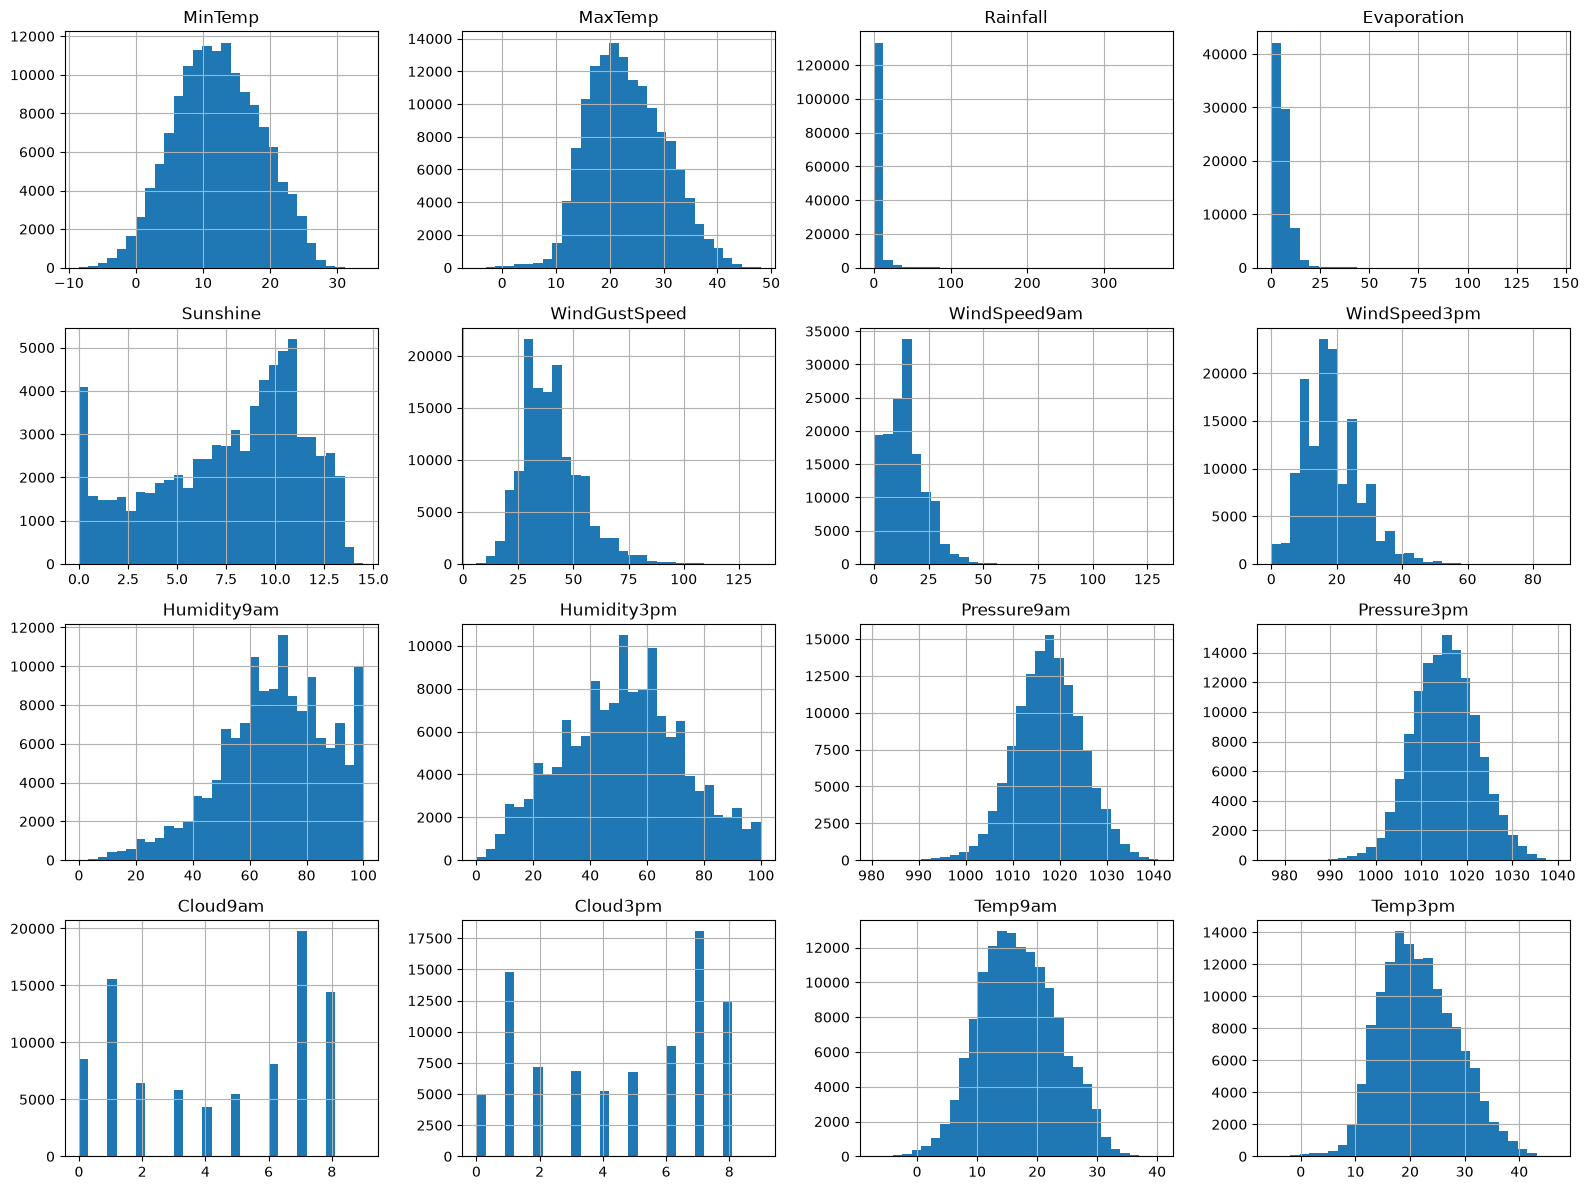

In [39]:
df.select_dtypes('number').hist(bins=30, figsize=(16, 12))
plt.tight_layout()

for c in df.select_dtypes('object'):
    print(c, df[c].nunique())

### Features vs Targets (Numeric)

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine',
       'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am',
       'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm',
       'Temp9am', 'Temp3pm'],
      dtype='str')


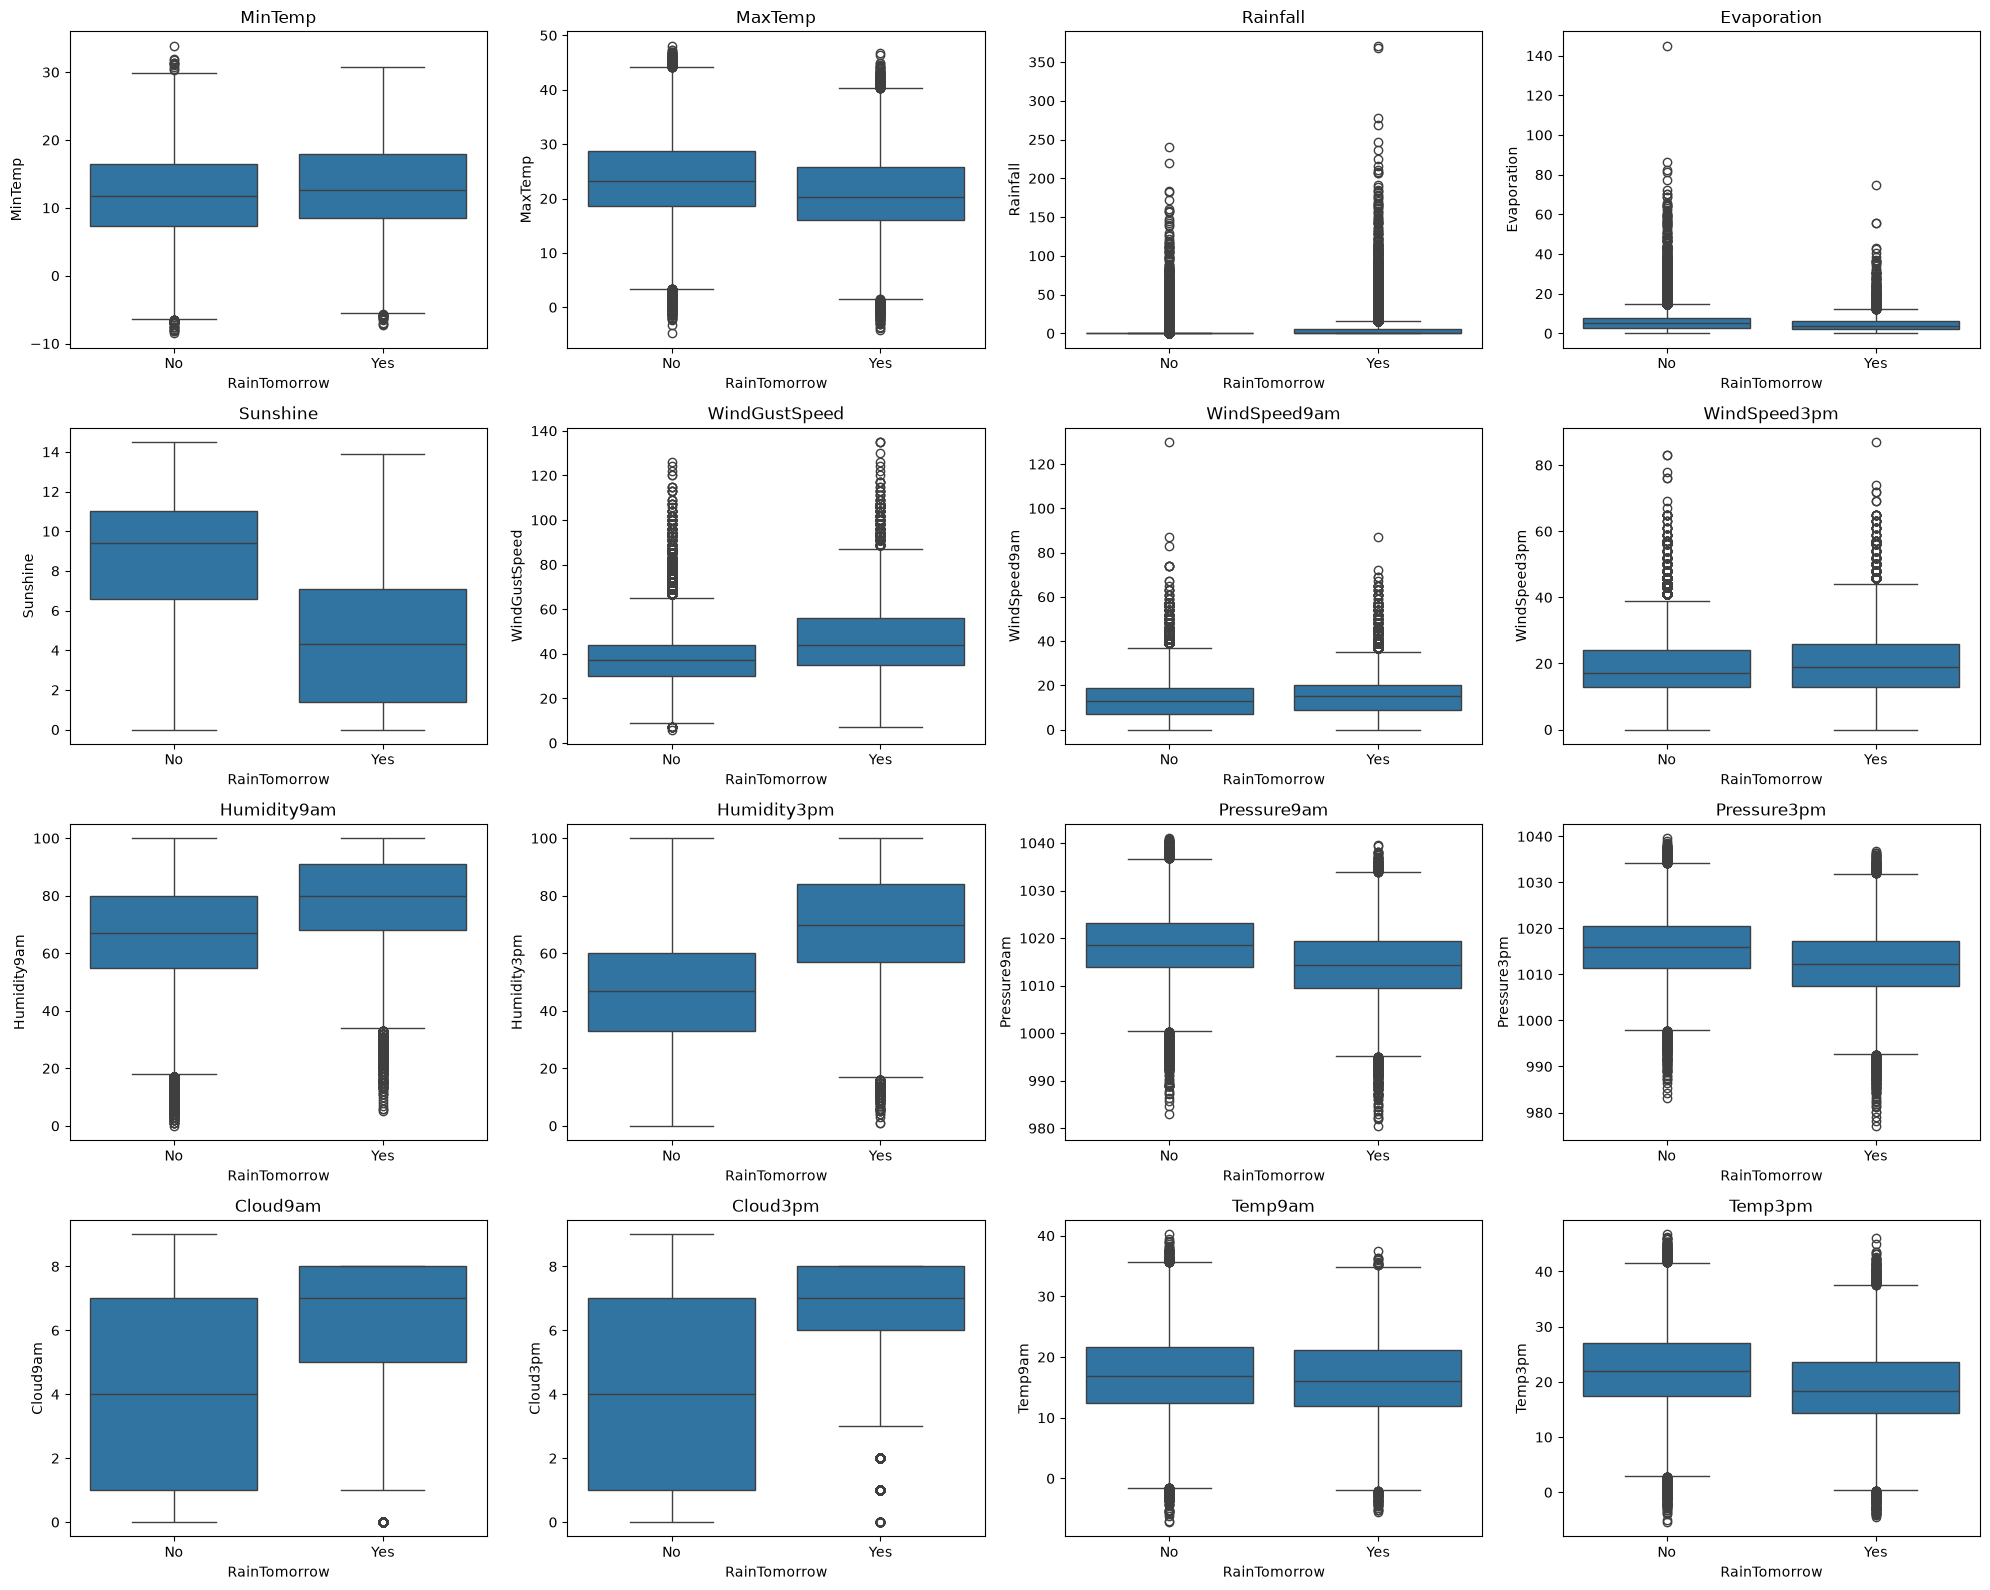

In [ ]:
numeric_cols = df.select_dtypes('number').columns

# There are 16 numeric features, based on the number of histograms above
fig, ax = plt.subplots(4, 4, figsize=(20, 16))
for ax, col in zip(ax.flat, numeric_cols):
    sns.boxplot(data=df, x='RainTomorrow', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()

### Features vs Target (Categorical)

RainToday
No     15.19
Yes    46.41
Name: RainTomorrow_bin, dtype: float64
Axes(0.125,0.11;0.775x0.77)


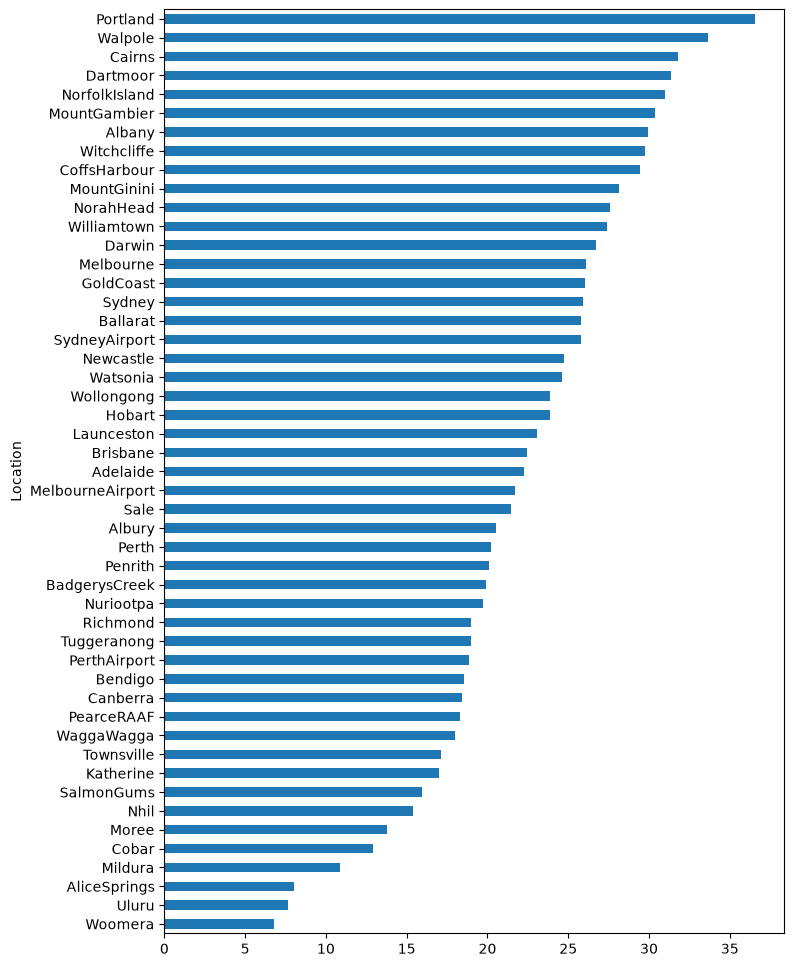

In [58]:
# Create a new column that transform the RainTomorrow value to binary (0 or 1)
df_temp = df.copy()
df_temp['RainTomorrow_bin'] = df_temp['RainTomorrow'].map({'No': 0, 'Yes': 1})

print((df_temp.groupby('RainToday')['RainTomorrow_bin'].mean()*100).round(2))

print(((df_temp.groupby('Location')['RainTomorrow_bin'].mean()*100).round(2).sort_values().plot(kind='barh', figsize=(8, 12))))

### Summary of Data

__Overall__
- There are all together **23 columns** in the WeatherAUS dataset.  The target column is <span style="color:chocolate">RainTomorrow</span>.
- There are a **few thousand rows** without target, around **2.2%** of the overall data.  These rows are being dropped as they won't help in training and validating our model.
- The classes in <span style="color:chocolate">RainTomorrow</span> are also imbalanced.  After dropping the rows with missing target, there are around **78% No** and **22% Yes**.  A model that always says "No" gets ~78% of accuracy.
- <span style="color:chocolate">Sunshine</span>, <span style="color:chocolate">Evaporation</span>, <span style="color:chocolate">Cloud3pm</span>, <span style="color:chocolate">Cloud9am</span> are missing a lot of data, around 37-48% of the rows.  
- There are many locations 100% missing the <span style="color:chocolate">Sunshine</span> or <span style="color:chocolate">Evaporation</span> features.  Missing features will be imputed with the **global median** of the corresponding feature if they are **numeric**.  For **categorical** columns, they will be imputed with the **mode**.
- <span style="color:chocolate">Rainfall</span> and <span style="color:chocolate">Evaporation</span> are heavily right-skewed.  Most days have zero rain but there are a few days with heavy rainfall.  For highly skewed feature, may consider using log to transform the data.
- <span style="color:chocolate">RainToday</span> and <span style="color:chocolate">RainTomorrow</span> are **Yes/No**.  They can be converted to binary values.
- <span style="color:chocolate">WindGustDir</span>, <span style="color:chocolate">WindDir9am</span>, and <span style="color:chocolate">WindDir3pm</span> have **16** unique values, which are the compass points.  They can be converted using **one-shot encoding**.
- <span style="color:chocolate">Location</span> has **49** values.  They can be converted using **one-shot encoding**.
- Based on the box-plot, these are the different classes of predictors, from strong to weak:
    - **Strong Predictors**: 
        - <span style="color:chocolate">Humidity3pm</span>: The 'No' median is about 47% and 'Yes' median is about 70%.  Higher humidity has a higher chance of rain tomorrow
        - <span style="color:chocolate">Sunshine</span>: The 'No' median is about 9 hours and the 'Yes' median is about 4 hours.  Fewer sun hours today implies a higher chance of rain tomorrow.
        - <span style="color:chocolate">Cloud3pm</span>: The 'No' median is about 4 and the 'Yes' median is about 7.  Late cloudiness of the day implies a higher chance of rain tomorrow.
        - Since Sunshine and Cloud3pm are the columns with the most missing values by location, they should be imputed instead of dropped.
    - **Moderate Predictors**:
        - <span style="color:chocolate">Humidity9am</span>: The 'No' median is about 65 and 'Yes' median is about 80
        - <span style="color:chocolate">Pressure9am</span>: The 'No' median is about 1018 and 'Yes' median is about 1015
        - <span style="color:chocolate">Pressure3pm</span>: The 'No' median is about 1016 and 'Yes' median is about 1011
    - **Weak Predictors**:
        - <span style="color:chocolate">MinTemp, Temp9am, WindSpeed9am, WindSpeed3pm</span>: There are very different in the median and range of the boxes among them.
- <span style="color:chocolate">Rainfall</span> and <span style="color:chocolate">Evaporation</span> are being squashed by the outliers.  

